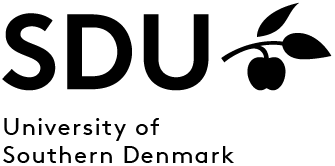
<br><br><br>
<p style="color: #789D4A;font-family: courier;font-size: 160%;text-align:center;">Optimization and Image Processing (E26)</p> 

<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Dr Till Leissner, Associate Professor</p> 
<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Mads Clausen Institute, University of Southern Denmark</p> 

# Problem 2.2 — Point operation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color, exposure, filters, util

try:
    import oip
except Exception:
    oip = None

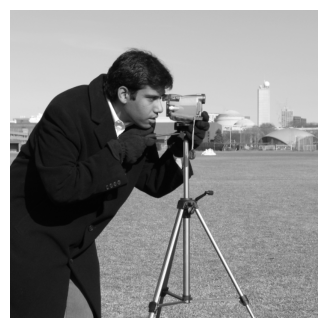

[[0.78431374 0.78431374 0.78431374 ... 0.7411765  0.74509805 0.74509805]
 [0.78431374 0.78039217 0.78039217 ... 0.74509805 0.74509805 0.74509805]
 [0.78039217 0.78039217 0.78039217 ... 0.74509805 0.74509805 0.74509805]
 ...
 [0.09803922 0.09803922 0.10588235 ... 0.54509807 0.47843137 0.5764706 ]
 [0.09803922 0.09803922 0.10196079 ... 0.61960787 0.5529412  0.65882355]
 [0.09803922 0.09803922 0.10588235 ... 0.5921569  0.59607846 0.58431375]]


In [9]:
image = oip.load_gray("camera", dtype=np.float32)
rgb = oip.load_rgb()
oip.show_image(image)
print(image)

## a) Implement gain/offset adjustment. 

*Suggestion:* You can use ipywidgets to create sliders

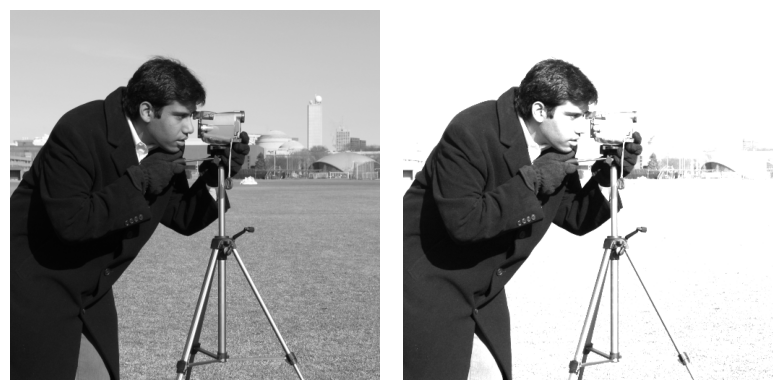

(<Figure size 800x400 with 2 Axes>, array([<Axes: >, <Axes: >], dtype=object))

In [31]:
def adjust_intensity(image, gain=1.0, offset=0.0):
    return np.clip(gain * image + offset, 0, 1)
    
adjusted = adjust_intensity(image, gain=2, offset=0.0)
oip.show_images(image,adjusted)

In [11]:
x = np.array([0.0, 0.5, 1.0])
assert np.allclose(adjust_intensity(x, 2, 0), [0,1,1])

## b) Implement inversion and thresholding.

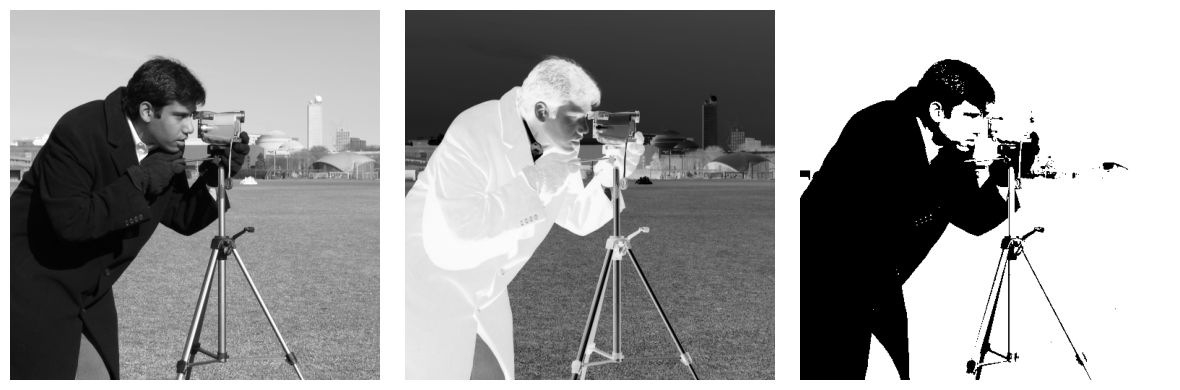

(<Figure size 1200x400 with 3 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >], dtype=object))

In [32]:
def invert(image):
    return 1 - image

def threshold(image, T):
    return image >= T

    
inverted = invert(image)
thresholded = threshold(image,0.3)
oip.show_images(image,inverted,thresholded)

In [ ]:
x = np.array([0.0, 0.25, 0.75, 1.0])
assert np.allclose(invert(x), [1.0, 0.75, 0.25, 0.0])
assert np.array_equal(threshold(x, 0.5), [False, False, True, True])

## c) Contrast stretching

Map min and max to 0 and 1.

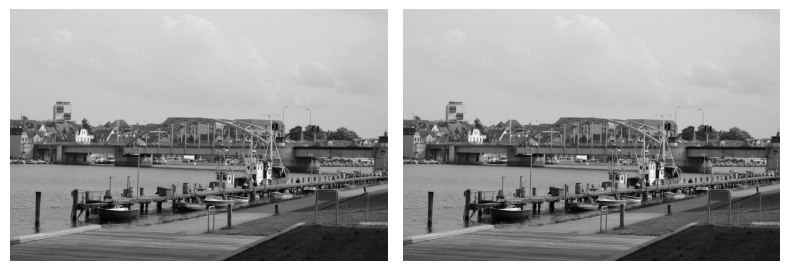

(<Figure size 800x400 with 2 Axes>, array([<Axes: >, <Axes: >], dtype=object))

In [33]:
def contrast_stretch(image):
    lo = image.min(); hi = image.max()
    if hi == lo:
        return np.zeros_like(image, dtype=float)
    return (image - lo) / (hi - lo)

grayf = oip.load_grey("IMG_5051-8bit.jpg", dtype=float)
stretched = contrast_stretch(grayf)
oip.show_images(grayf,stretched)

In [ ]:
x = np.array([2.0, 4.0, 6.0])
assert np.allclose(contrast_stretch(x), [0.0, 0.5, 1.0])

## d) Gamma correction

Implement gamma correction.

In [ ]:
def gamma_correct(image, gamma):
    return np.clip(image, 0, 1) ** gamma
    
grayf = oip.load_grey("IMG_5051-8bit.jpg", dtype=float)
gamma_corrected = gamma_correct(grayf,2.2)
oip.show_images(grayf,gamma_corrected)

In [ ]:
x = np.array([0.0, 0.25, 1.0])
assert np.allclose(gamma_correct(x, 0.5), [0.0, 0.5, 1.0])

## e) Histogram equalisation

Implement equalisation using a CDF lookup table.

In [ ]:
def equalize_uint8(image):
    hist, _ = np.histogram(image, bins=256, range=(0, 256))
    cdf = np.cumsum(hist) / hist.sum()
    lut = np.floor(255 * cdf).astype(np.uint8)
    return lut[image]

image = oip.load_grey("moon", dtype=np.uint8)
eq = equalize_uint8(image)
oip.show_images(image,eq)
oip.show_histogram(image,cumulative=True)
oip.show_histogram(eq,cumulative=True)

In [ ]:
image = oip.load_grey("moon", dtype=np.uint8)
eq = equalize_uint8(image)
assert eq.shape == image.shape
assert eq.dtype == np.uint8

## f) Applied thresholding

Threshold a page-like image and estimate dark-pixel fraction.

In [ ]:
image = oip.load_grey("page", dtype=float)
T = filters.threshold_otsu(image)
ink = image < T
ink_fraction = float(ink.mean())
print(T, ink_fraction)

In [ ]:
assert 0 <= T <= 1
assert ink.dtype == bool
assert 0 < ink_fraction < 1